<a href="https://colab.research.google.com/github/aditya01-dev/Natural-Language-Processing-Lab/blob/main/NLP_Practical_19_Opinion_Mining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PRODUCT REVIEW DATASET


,Review_ID,Review
0,1,The battery backup is excellent and the camera...
1,2,The battery drains quickly and the camera qual...
2,3,The display is bright and the screen quality i...
3,4,The screen is dull and the display quality is ...
4,5,The phone performance is smooth and the proces...
5,6,The phone has poor performance and apps lag fr...
6,7,The price is reasonable and offers excellent v...
7,8,The product is expensive and not worth its price.
8,9,The delivery was fast and the packaging was ex...
9,10,The delivery was delayed and the packaging was...



REVIEW-LEVEL SENTIMENT ANALYSIS


,Review_ID,Review,Compound_Score,Sentiment
0,1,The battery backup is excellent and the camera...,0.8225,Positive
1,2,The battery drains quickly and the camera qual...,-0.5256,Negative
2,3,The display is bright and the screen quality i...,0.7717,Positive
3,4,The screen is dull and the display quality is ...,-0.7096,Negative
4,5,The phone performance is smooth and the proces...,0.0000,Neutral
5,6,The phone has poor performance and apps lag fr...,-0.6705,Negative
6,7,The price is reasonable and offers excellent v...,0.7269,Positive
7,8,The product is expensive and not worth its price.,-0.1695,Negative
8,9,The delivery was fast and the packaging was ex...,0.5719,Positive
9,10,The delivery was delayed and the packaging was...,-0.5859,Negative



ASPECT-WISE OPINION EXTRACTION


,Review_ID,Aspect,Opinion,Compound_Score,Sentiment
0,1,Battery,The battery backup is excellent and the camera...,0.8225,Positive
1,1,Camera,The battery backup is excellent and the camera...,0.8225,Positive
2,2,Battery,The battery drains quickly and the camera qual...,-0.5256,Negative
3,2,Camera,The battery drains quickly and the camera qual...,-0.5256,Negative
4,3,Display,The display is bright and the screen quality i...,0.7717,Positive
5,4,Display,The screen is dull and the display quality is ...,-0.7096,Negative
6,5,Performance,The phone performance is smooth and the proces...,0.0000,Neutral
7,6,Performance,The phone has poor performance and apps lag fr...,-0.6705,Negative
8,7,Price,The price is reasonable and offers excellent v...,0.7269,Positive
9,8,Price,The product is expensive and not worth its price.,-0.1695,Negative



ASPECT-WISE SENTIMENT SUMMARY


,Total_Opinions,Positive,Negative,Neutral,Average_Score,Overall_Opinion
Aspect,,,,,,
Battery,2,1,1,0,0.148,Positive
Camera,2,1,1,0,0.148,Positive
Customer Service,2,1,1,0,0.316,Positive
Delivery,2,1,1,0,-0.007,Positive
Display,2,1,1,0,0.031,Positive
Performance,2,0,1,1,-0.335,Negative
Price,2,1,1,0,0.279,Positive


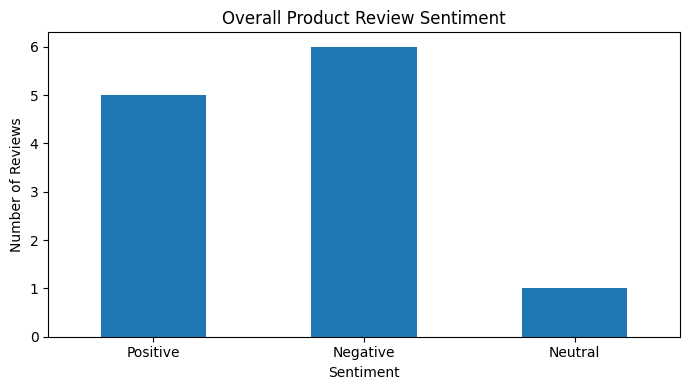

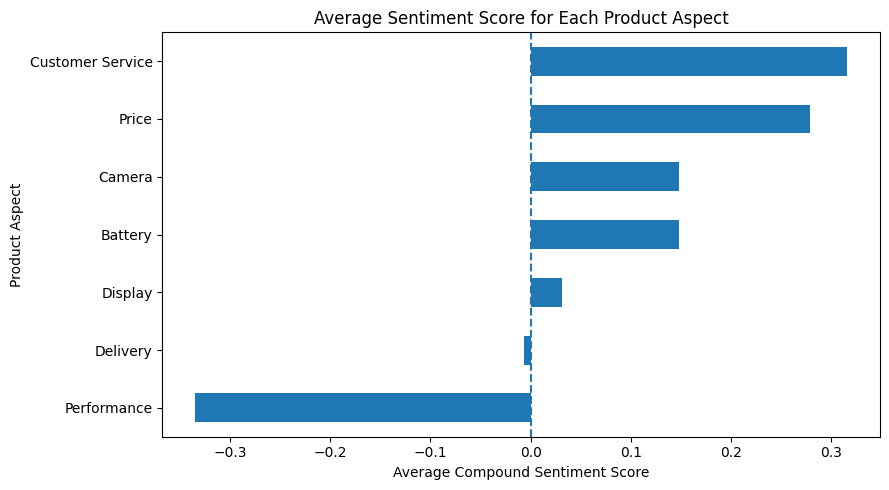


NEW REVIEW ANALYSIS
Review: The camera is excellent but the battery backup is poor.
Sentiment Score: -0.421
Overall Sentiment: Negative

Aspect-wise opinions in the new review:
Battery -> Negative
Camera -> Negative

RESULT:
Opinion mining was performed successfully on the product
review dataset using VADER sentiment analysis.

CONCLUSION:
The system identified overall review sentiment and extracted
aspect-wise opinions about different product features.


In [ ]:

# Name: Aditya kumar Singh# ============================================================
# PRACTICAL 19: OPINION MINING ON PRODUCT REVIEWS DATASET
# Course Outcome: CO2
# ============================================================

# OBJECTIVE:
# To perform opinion mining on product reviews by identifying
# overall sentiment and extracting aspect-wise opinions.

# Install required library
!pip -q install vaderSentiment

# Import libraries
import re
import pandas as pd
import matplotlib.pyplot as plt
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from IPython.display import display

# ------------------------------------------------------------
# 1. CREATE SAMPLE PRODUCT REVIEW DATASET
# ------------------------------------------------------------

reviews = [
    "The battery backup is excellent and the camera takes beautiful photos.",
    "The battery drains quickly and the camera quality is very poor.",
    "The display is bright and the screen quality is amazing.",
    "The screen is dull and the display quality is disappointing.",
    "The phone performance is smooth and the processor is very fast.",
    "The phone has poor performance and apps lag frequently.",
    "The price is reasonable and offers excellent value for money.",
    "The product is expensive and not worth its price.",
    "The delivery was fast and the packaging was excellent.",
    "The delivery was delayed and the packaging was damaged.",
    "Customer service was helpful and the support team resolved my issue.",
    "The service was terrible and customer support was unhelpful."
]

df = pd.DataFrame({
    "Review_ID": range(1, len(reviews) + 1),
    "Review": reviews
})

print("PRODUCT REVIEW DATASET")
display(df)

# ------------------------------------------------------------
# 2. INITIALIZE SENTIMENT ANALYZER
# ------------------------------------------------------------

analyzer = SentimentIntensityAnalyzer()

def classify_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

# ------------------------------------------------------------
# 3. REVIEW-LEVEL SENTIMENT ANALYSIS
# ------------------------------------------------------------

df["Compound_Score"] = df["Review"].apply(
    lambda text: analyzer.polarity_scores(text)["compound"]
)

df["Sentiment"] = df["Compound_Score"].apply(classify_sentiment)

print("\nREVIEW-LEVEL SENTIMENT ANALYSIS")
display(df[["Review_ID", "Review", "Compound_Score", "Sentiment"]])

# ------------------------------------------------------------
# 4. ASPECT-BASED OPINION MINING
# ------------------------------------------------------------

aspects = {
    "Battery": ["battery", "charging", "charge", "backup"],
    "Camera": ["camera", "photo", "photos", "picture", "video"],
    "Display": ["display", "screen"],
    "Performance": ["performance", "speed", "lag", "processor", "apps"],
    "Price": ["price", "cost", "expensive", "affordable", "value"],
    "Delivery": ["delivery", "shipping", "arrived", "packaging"],
    "Customer Service": ["service", "support", "staff", "customer"]
}

aspect_records = []

for _, row in df.iterrows():
    sentences = re.split(r"(?<=[.!?])\s+", row["Review"])

    for sentence in sentences:
        sentence_lower = sentence.lower()

        for aspect, keywords in aspects.items():
            if any(keyword in sentence_lower for keyword in keywords):
                score = analyzer.polarity_scores(sentence)["compound"]

                aspect_records.append({
                    "Review_ID": row["Review_ID"],
                    "Aspect": aspect,
                    "Opinion": sentence,
                    "Compound_Score": score,
                    "Sentiment": classify_sentiment(score)
                })

aspect_df = pd.DataFrame(aspect_records)

print("\nASPECT-WISE OPINION EXTRACTION")
display(aspect_df)

# ------------------------------------------------------------
# 5. ASPECT-WISE SENTIMENT SUMMARY
# ------------------------------------------------------------

aspect_summary = aspect_df.groupby("Aspect").agg(
    Total_Opinions=("Sentiment", "count"),
    Positive=("Sentiment", lambda x: (x == "Positive").sum()),
    Negative=("Sentiment", lambda x: (x == "Negative").sum()),
    Neutral=("Sentiment", lambda x: (x == "Neutral").sum()),
    Average_Score=("Compound_Score", "mean")
).round(3)

aspect_summary["Overall_Opinion"] = aspect_summary[
    ["Positive", "Negative", "Neutral"]
].idxmax(axis=1)

print("\nASPECT-WISE SENTIMENT SUMMARY")
display(aspect_summary)

# ------------------------------------------------------------
# 6. OVERALL SENTIMENT DISTRIBUTION
# ------------------------------------------------------------

sentiment_counts = df["Sentiment"].value_counts()

plt.figure(figsize=(7, 4))
sentiment_counts.reindex(
    ["Positive", "Negative", "Neutral"], fill_value=0
).plot(kind="bar")
plt.title("Overall Product Review Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. ASPECT-WISE SENTIMENT VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))
aspect_summary["Average_Score"].sort_values().plot(kind="barh")
plt.title("Average Sentiment Score for Each Product Aspect")
plt.xlabel("Average Compound Sentiment Score")
plt.ylabel("Product Aspect")
plt.axvline(0, linestyle="--")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. ANALYZE A NEW PRODUCT REVIEW
# ------------------------------------------------------------

new_review = "The camera is excellent but the battery backup is poor."

new_score = analyzer.polarity_scores(new_review)["compound"]

print("\nNEW REVIEW ANALYSIS")
print("Review:", new_review)
print("Sentiment Score:", round(new_score, 3))
print("Overall Sentiment:", classify_sentiment(new_score))

print("\nAspect-wise opinions in the new review:")

for aspect, keywords in aspects.items():
    if any(keyword in new_review.lower() for keyword in keywords):
        print(aspect, "->",
              classify_sentiment(
                  analyzer.polarity_scores(new_review)["compound"]
              ))

# ------------------------------------------------------------
# 9. RESULT AND CONCLUSION
# ------------------------------------------------------------

print("\nRESULT:")
print("Opinion mining was performed successfully on the product")
print("review dataset using VADER sentiment analysis.")

print("\nCONCLUSION:")
print("The system identified overall review sentiment and extracted")
print("aspect-wise opinions about different product features.")